<a href="https://colab.research.google.com/github/SarahiVargas127/Simulacion-Estocastica/blob/main/Proyecto_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

<h1>UNIVERSIDAD JUÁREZ DEL ESTADO DE DURANGO</h1>
<h3>Facultad de Ciencias Exactas · Maestría en Estadística Aplicada</h3>

<br>
<hr width="60%">
<br>

<h2>PROYECTO FINAL</h2>
<h1>Evaluación estocástica del viento: Oaxaca (Istmo) frente a Victoria de Durango</h1>

<br>
<hr width="60%">
<br>

<p><b>Asignatura:</b> Simulación Estocástica</p>
<p><b>Docente:</b> Dr. Gerónimo Quiñónez-Barraza</p>
<p><b>Alumna:</b> Angeles Sarahí Vargas Gutiérrez</p>
<p><b>Fecha:</b> Noviembre de 2026</p>

</div>


## Índice

* [Resumen](#resumen)
* [1. Planteamiento](#sec1)
  * [Contexto y justificación de la simulación estocástica](#sec1-contexto)
  * [1.1 Variables](#sec1-1)
  * [1.2 Formulación estadística y supuestos](#sec1-2)
* [2. Configuración](#sec2)
* [3. Datos: NASA POWER](#sec3)
* [4. Comportamiento del viento año por año (2023–2026)](#sec4)
* [5. Modelo probabilístico: distribución de la velocidad](#sec5)
* [6. Modelo estocástico: cadena de Markov con ciclo mensual](#sec6)
  * [Relación entre horas consecutivas](#sec6-rel)
  * [Validación del modelo (dentro de muestra)](#sec6-val)
  * [Validación fuera de muestra (2026)](#sec6-bt)
* [7. Proyección 2027–2029](#sec7)
  * [Convergencia del Monte Carlo](#sec7-conv)
  * [Escenarios de sensibilidad del viento](#sec7-esc)
* [8. Viabilidad: ¿cumple cada sitio los criterios para un parque eólico?](#sec8)
  * [Sensibilidad al exponente de la ley de potencia](#sec8-alfa)
  * [Sensibilidad a las velocidades del aerogenerador](#sec8-turb)
* [9. Conclusiones](#sec9)
* [Limitaciones](#limitaciones)
* [Referencias](#referencias)

## Resumen

Se compara el viento de una zona de alto recurso (Istmo de Tehuantepec, Oaxaca) con el de Victoria de Durango usando series horarias de NASA POWER de 2023 a 2026. Se describe el comportamiento de cada año, se modela el viento con una distribución Weibull y con una cadena de Markov con ciclo mensual, y se proyectan los años 2027 a 2029 con simulación Monte Carlo. Con los resultados se evalúa si cada sitio cumple criterios de referencia para un parque eólico.





## 1. Planteamiento

**Pregunta.** ¿Cómo se comporta el viento año con año en Oaxaca (Istmo) y en Victoria de Durango, qué se puede esperar para 2027-2029 y qué tan viable es cada sitio para un parque eólico?

**Objetivos.**
1. Comparar el comportamiento del viento de cada año entre 2023 y 2026.
2. Modelar el viento con una distribución de probabilidad y con una cadena de Markov.
3. Proyectar 2027-2029 mediante simulación Monte Carlo.
4. Evaluar la viabilidad con criterios de referencia (viento medio y factor de capacidad).

**Alcance.** Se evalúa únicamente el **recurso de viento**. Que una región sea apta para un parque eólico depende además de la red de transmisión, el terreno y los costos. Las conclusiones sobre Durango se refieren al punto analizado (Victoria de Durango) y no necesariamente a todo el estado.

### Contexto y justificación de la simulación estocástica

La energía eólica es una de las fuentes renovables con mayor crecimiento en México. Según datos reportados por Energía Estratégica (s. f.), el país tiene alrededor de 8 GW eólicos instalados y Oaxaca concentra la mayor capacidad (2,758 MW), seguido de Tamaulipas (1,715 MW) y Nuevo León (961 MW). Contrastar un sitio de alto recurso con Victoria de Durango permite evaluar qué tan distinto es el viento y qué implica para un parque eólico.

**Por qué simulación estocástica.**
1. El viento es una variable aleatoria con estacionalidad y dependencia temporal: la velocidad de una hora depende de la anterior.
2. La energía producida es una función **no lineal** de la velocidad (cúbica entre el arranque y la velocidad nominal, con saturación). Por eso la energía esperada no se obtiene evaluando la curva de potencia en la velocidad media, ya que $E[P(V)]\neq P(E[V])$.
3. Con pocos años de datos no se puede cuantificar el rango de producción plausible. La simulación Monte Carlo genera muchos años posibles y permite estimar la incertidumbre, calcular la probabilidad de cumplir criterios de viabilidad y comparar escenarios.

**Fuente de datos.** Series horarias de velocidad del viento de NASA POWER (sección 3).

### 1.1 Variables

**Tabla 1.** *Descripción de las variables de respuesta, predictoras, factores de comparación y parámetros de entrada del modelo.*

| Tipo | Variable | Descripción |
|---|---|---|
| Respuesta (Y) | $v_t$ | Velocidad horaria del viento a 80 m (m/s) |
| Respuesta derivada (Y) | $\bar v$ | Viento medio anual (m/s) |
| Respuesta derivada (Y) | $CF$ | Factor de capacidad anual: energía producida entre la que daría el aerogenerador a potencia nominal todo el año |
| Predictora (X) | Localidad | Oaxaca (Istmo) o Victoria de Durango |
| Predictora (X) | Mes $m$ | Captura la estacionalidad del viento |
| Predictora (X) | Estado en la hora anterior $S_{t-1}$ | Captura la dependencia temporal (memoria) del viento; es la variable que usa la cadena de Markov |
| Factor de comparación | Año | Permite comparar 2023-2026 y proyectar 2027-2029 (no entra al modelo como predictora, porque el modelo no incluye tendencia) |
| Parámetros de entrada | $\alpha$, $v_{arranque}$, $v_{nominal}$, $v_{corte}$ | Exponente de la ley de potencia y velocidades del aerogenerador (sección 2) |


### 1.2 Formulación estadística y supuestos

**Modelo general.** El problema se formula como

$$y_t=f(\mathbf{X}_t;\boldsymbol{\theta})+\varepsilon_t,$$

donde $y_t=v_t$ es la velocidad horaria del viento a 80 m (variable objetivo); $\mathbf{X}_t=(m_t,\,S_{t-1})$ reúne las variables predictoras (el mes y el estado del viento en la hora anterior), una versión por localidad; $\boldsymbol{\theta}=\{p^{(m)}_{ij},\,\mu^{(m)}_j,\,\alpha\}$ son los parámetros (probabilidades de transición, velocidad media de cada estado y exponente de la ley de potencia); $f(\mathbf{X}_t;\boldsymbol{\theta})=\sum_j p^{(m)}_{ij}\,\mu^{(m)}_j$, con $i=S_{t-1}$, es la velocidad esperada dada la información disponible; y $\varepsilon_t=v_t-f(\mathbf{X}_t;\boldsymbol{\theta})$ es el componente aleatorio, con $E[\varepsilon_t\mid\mathbf{X}_t]=0$, cuya distribución surge de la transición aleatoria entre estados y del remuestreo de velocidades dentro de cada estado. A partir de $y_t$ se obtienen las respuestas anuales $\bar v$ y $CF$.

**Extrapolación a la altura del buje.** $v_{80}=v_{50}\,(80/50)^{\alpha}$, con $\alpha=1/7$.

**Distribución del viento.** Se modela con la Weibull de forma $k$ y escala $\lambda$:

$$f(v)=\frac{k}{\lambda}\left(\frac{v}{\lambda}\right)^{k-1}e^{-(v/\lambda)^k},\qquad F(v)=1-e^{-(v/\lambda)^k},\qquad v>0.$$

Los parámetros se estiman por máxima verosimilitud. Para generar valores se usa la transformada inversa: $V=\lambda\,[-\ln(1-U)]^{1/k}$, con $U\sim U(0,1)$.

**Cadena de Markov con ciclo mensual.** Se discretiza la velocidad en $K=5$ estados $S_t\in\{1,\dots,5\}$ (calma, baja, moderada, alta y muy alta). Dado el mes $m$,

$$P(S_{t+1}=j\mid S_t=i)=p^{(m)}_{ij},\qquad \hat p^{(m)}_{ij}=\frac{n^{(m)}_{ij}}{n^{(m)}_{i\cdot}},$$

donde $n^{(m)}_{ij}$ cuenta las transiciones de $i$ a $j$ observadas en una ventana de tres meses (el mes $m$ y sus vecinos). La simulación usa la transformada inversa discreta: $S_{t+1}=\min\{j:\ U\le \sum_{l\le j}p^{(m)}_{il}\}$. Dentro de cada estado, la velocidad se obtiene remuestreando velocidades observadas en ese estado.

**Aerogenerador y factor de capacidad.** La potencia normalizada (fracción de la nominal) es

$$
P(v)=\begin{cases}
0 & v<v_{arranque}\ \text{ o }\ v\ge v_{corte}\\[2pt]
\dfrac{v^3-v_{arranque}^3}{v_{nominal}^3-v_{arranque}^3} & v_{arranque}\le v<v_{nominal}\\[8pt]
1 & v_{nominal}\le v<v_{corte}
\end{cases}
\qquad CF=\frac{1}{8760}\sum_{t=1}^{8760}P(v_t).
$$

**Monte Carlo.** Para cada año proyectado se simulan $N$ trayectorias de 8,760 horas. De cada resultado (por ejemplo, el CF) se estiman la media, los cuantiles del 5% y del 95%, y probabilidades como la proporción de simulaciones que cumplen un criterio. El error estándar del estimador de la media es $s/\sqrt{N}$.

**Supuestos.**
1. La serie de reanálisis de NASA POWER representa el viento del punto elegido.
2. Dado el mes, el estado del viento sigue una cadena de Markov de primer orden: solo importa la hora anterior.
3. El viento es estacionario entre años: se usan las mismas matrices en 2027-2029, sin tendencia.
4. Los años proyectados son independientes entre sí.
5. Una ley de potencia con exponente fijo describe el aumento del viento con la altura.
6. El aerogenerador es genérico, con curva de potencia simplificada y sin pérdidas.
7. Cada año tiene 8,760 horas (no se considera el día bisiesto).

## 2. Configuración

Todos los supuestos están en esta celda. Para cambiar el periodo, las coordenadas o los umbrales, modifícalos aquí y vuelve a ejecutar.

- **Altura:** NASA POWER da el viento a 50 m; se extrapola a 80 m (altura del buje) con una ley de potencia de exponente 1/7 (supuesto típico).
- **Aerogenerador genérico:** arranque a 3 m/s, potencia nominal a 12 m/s y corte a 25 m/s, dentro de los rangos típicos (sección 8).
- **Coordenadas:** verifícalas en un mapa. El punto de Oaxaca está en el corredor eólico del Istmo de Tehuantepec (Unión Hidalgo). Si cambias las coordenadas, la descarga se repite sola, porque el archivo guardado incluye la latitud y la longitud en su nombre.

In [ ]:
import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
rng = np.random.default_rng(SEED)

# ----- Periodo: de enero de ANIO_INI al último dato disponible de ANIO_FIN
ANIO_INI, ANIO_FIN = 2023, 2026
FECHA_ULTIMO_DATO = "2026-11-01"  # fecha fija para que los resultados sean reproducibles (None = hoy menos 7 días)
ANIOS_PROY = [2027, 2028, 2029]   # años a proyectar

# ----- Localidades (latitud, longitud aproximadas)
LOCALIDADES = {
    "Oaxaca (Istmo)":      {"lat": 16.449, "lon": -94.850},   # Unión Hidalgo, Istmo de Tehuantepec
    "Victoria de Durango": {"lat": 24.03, "lon": -104.65},
}
PARAMETRO = "WS50M"                                   # viento a 50 m (m/s)
ALTURA_BASE, ALTURA_BUJE, ALFA = 50.0, 80.0, 1/7

# ----- Aerogenerador genérico (m/s)
V_ARRANQUE, V_NOMINAL, V_CORTE = 3.0, 12.0, 25.0

# ----- Cadena de Markov: estados por velocidad (m/s)
BORDES_ESTADOS = [0, 3, 6, 9, 12, np.inf]
NOMBRES_ESTADOS = ["Calma", "Baja", "Moderada", "Alta", "Muy alta"]
K = len(NOMBRES_ESTADOS)
MESES_MOSTRAR = [1, 4, 7, 10]       # meses cuyas matrices se muestran en la gráfica

# ----- Simulación y criterios
N_SIM = 1000                      # años simulados por cada año proyectado
HORAS_ANIO = 8760
MIN_HORAS_MES = 600               # un mes necesita al menos estas horas para graficarse
UMBRAL_VIENTO = 6.5               # m/s a 80 m (regla práctica, sección 8)
CF_UMBRAL = 0.30                  # factor de capacidad de referencia (sección 8)
ESCENARIOS_VIENTO = {"Viento -5%": 0.95, "Escenario base": 1.00, "Viento +5%": 1.05}   # sección 7

COLORES = dict(zip(LOCALIDADES, ["tab:blue", "tab:orange"]))

## 3. Datos: NASA POWER

Se descargan series **horarias** de velocidad del viento a 50 m, un año por solicitud, hasta el último dato disponible, y se guardan en la carpeta `datos_nasa_power` para no repetir la descarga.

Para interpretar bien los datos:
- Provienen de **reanálisis (MERRA-2)**, no de una estación: cada punto devuelve el valor de una celda de unos 50 km y **no captura el relieve local**.
- **2026 es un año parcial.** Las estadísticas anuales usan solo años completos; el año parcial se reporta aparte.

**Descripción de los datos**

**Tabla 2.** *Características técnicas, resolución espacio-temporal y cobertura de los datos meteorológicos obtenidos de NASA POWER.*

| Característica | Detalle |
|---|---|
| Fuente | NASA POWER (reanálisis MERRA-2), acceso por API |
| Variable | `WS50M`: velocidad del viento a 50 m (m/s) |
| Resolución temporal | Horaria |
| Resolución espacial | Celda de aproximadamente 0.5° × 0.625° (unos 50 km) |
| Periodo | Del 1 de enero de 2023 al 1 de noviembre de 2026 |
| Tamaño | 33,600 horas por localidad |
| Localidades | Oaxaca (Istmo, Unión Hidalgo): 16.449° N, 94.850° O; Victoria de Durango: 24.03° N, 104.65° O |


In [ ]:
URL_NASA = "https://power.larc.nasa.gov/api/temporal/hourly/point"
CARPETA_CACHE = "datos_nasa_power"
os.makedirs(CARPETA_CACHE, exist_ok=True)

if FECHA_ULTIMO_DATO is None:
    FECHA_FIN_DATOS = pd.Timestamp.today().normalize() - pd.Timedelta(days=7)
else:
    FECHA_FIN_DATOS = pd.Timestamp(FECHA_ULTIMO_DATO)
FECHA_FIN_DATOS = min(FECHA_FIN_DATOS, pd.Timestamp(f"{ANIO_FIN}-12-31"))


def descargar_nasa_power(lat, lon, anio_ini, anio_fin, fecha_fin, parametro=PARAMETRO, reintentos=3):
    """Serie horaria de NASA POWER, un anio por solicitud, hasta fecha_fin."""
    partes = []
    for anio in range(anio_ini, anio_fin + 1):
        inicio = pd.Timestamp(f"{anio}-01-01")
        fin = min(pd.Timestamp(f"{anio}-12-31"), fecha_fin)
        if fin < inicio:
            continue
        params = {"parameters": parametro, "community": "RE", "longitude": lon, "latitude": lat,
                  "start": inicio.strftime("%Y%m%d"), "end": fin.strftime("%Y%m%d"), "format": "JSON"}
        for intento in range(reintentos):
            try:
                r = requests.get(URL_NASA, params=params, timeout=180)
                r.raise_for_status()
                datos_anio = r.json()["properties"]["parameter"][parametro]
                break
            except Exception as e:
                if intento == reintentos - 1:
                    raise RuntimeError(f"Fallo la descarga de {anio}: {e}")
                time.sleep(5)
        s = pd.Series(datos_anio, dtype=float)
        s.index = pd.to_datetime(s.index, format="%Y%m%d%H")
        partes.append(s)
    serie = pd.concat(partes).sort_index()
    return serie.where(serie > -990)               # -999 = dato faltante


def cargar_serie(nombre, lat, lon):
    archivo = os.path.join(CARPETA_CACHE, re.sub(r"\W+", "_", nombre)
                           + f"_{PARAMETRO}_{lat:.3f}_{lon:.3f}_{ANIO_INI}_{FECHA_FIN_DATOS:%Y%m%d}.csv")
    if os.path.exists(archivo):
        return pd.read_csv(archivo, index_col=0, parse_dates=True).iloc[:, 0]
    print(f"Descargando {nombre} ...")
    s = descargar_nasa_power(lat, lon, ANIO_INI, ANIO_FIN, FECHA_FIN_DATOS)
    s.to_csv(archivo)
    return s


datos, V = {}, {}
for nombre, c in LOCALIDADES.items():
    s50 = cargar_serie(nombre, c["lat"], c["lon"])
    faltantes = int(s50.isna().sum())
    s50 = s50.interpolate(limit=6, limit_area="inside").dropna()
    df = pd.DataFrame({"v50": s50})
    df["v"] = df["v50"] * (ALTURA_BUJE / ALTURA_BASE) ** ALFA      # viento a la altura del buje
    df["anio"], df["mes"] = df.index.year, df.index.month
    datos[nombre], V[nombre] = df, df["v"].to_numpy()
    print(f"{nombre}: {len(df):,} horas ({df.index.min():%Y-%m-%d} a {df.index.max():%Y-%m-%d}); "
          f"faltantes: {faltantes}")


def anios_completos(df, minimo=0.95):
    horas = df.groupby("anio").size()
    return horas[horas >= minimo * HORAS_ANIO].index.tolist()


ANIOS_COMPLETOS = sorted(int(a) for a in set.intersection(*[set(anios_completos(d)) for d in datos.values()]))
ANIOS_PARCIALES = sorted(int(a) for a in set.union(*[set(d["anio"].unique()) for d in datos.values()])
                         - set(ANIOS_COMPLETOS))
print("Años completos:", ANIOS_COMPLETOS, "| Año(s) parcial(es):", ANIOS_PARCIALES)

Oaxaca (Istmo): 33,624 horas (2023-01-01 a 2026-11-01); faltantes: 0
Victoria de Durango: 33,624 horas (2023-01-01 a 2026-11-01); faltantes: 0
Años completos: [2023, 2024, 2025] | Año(s) parcial(es): [2026]


## 4. Comportamiento del viento año por año (2023-2026)

La primera gráfica pone en un solo lugar el viento medio de cada mes para cada año, en cada localidad, de modo que se puedan comparar los años entre sí y ver la estacionalidad. La tabla resume cada año: viento medio, porcentaje de horas por debajo de la velocidad de arranque y factor de capacidad (CF), que es la energía producida entre la que daría el aerogenerador a potencia nominal todo el año.

In [ ]:
from IPython.display import display, Markdown

def potencia_normalizada(v, v_ar=None, v_nom=None, v_cor=None):
    """Potencia de un aerogenerador genérico (fracción de la nominal)."""
    v_ar = V_ARRANQUE if v_ar is None else v_ar
    v_nom = V_NOMINAL if v_nom is None else v_nom
    v_cor = V_CORTE if v_cor is None else v_cor
    p = np.zeros(v.shape, dtype=float)
    m1 = (v >= v_ar) & (v < v_nom)
    p[m1] = (v[m1] ** 3 - v_ar ** 3) / (v_nom ** 3 - v_ar ** 3)
    p[(v >= v_nom) & (v < v_cor)] = 1.0
    return p

MEDIA_ANUAL, CF_ANUAL, filas = {}, {}, []
for nombre, df in datos.items():
    MEDIA_ANUAL[nombre] = df.groupby("anio")["v"].mean()
    CF_ANUAL[nombre] = df.groupby("anio")["v"].apply(lambda s: potencia_normalizada(s.to_numpy()).mean())
    for anio, g in df.groupby("anio"):
        filas.append({"Localidad": nombre,
                      "Año": f"{anio}" + (" (parcial)" if anio in ANIOS_PARCIALES else ""),
                      "Horas": len(g), "Viento medio (m/s)": g["v"].mean(), "Desv. est.": g["v"].std(),
                      "% horas < arranque": 100 * (g["v"] < V_ARRANQUE).mean(),
                      "Factor de capacidad": CF_ANUAL[nombre].loc[anio]})

tabla_anual = pd.DataFrame(filas).set_index(["Localidad", "Año"]).round(3)

display(Markdown("**Tabla 3.** \n*Estadísticas descriptivas anuales de la velocidad del viento a 80 m y factor de capacidad por localidad (2023–2026).*"))
display(tabla_anual)


**Tabla 3.** 
*Estadísticas descriptivas anuales de la velocidad del viento a 80 m y factor de capacidad por localidad (2023–2026).*

Horas  Viento medio (m/s)  Desv. est.  \
Localidad           Año                                                     
Oaxaca (Istmo)      2023             8760               7.686       3.919   
                    2024             8784               7.356       3.689   
                    2025             8760               7.494       3.767   
                    2026 (parcial)   7320               7.679       3.818   
Victoria de Durango 2023             8760               5.186       2.611   
                    2024             8784               5.559       2.948   
                    2025             8760               5.130       2.752   
                    2026 (parcial)   7320               4.659       2.372   

                                    % horas < arranque  Factor de capacidad  
Localidad           Año                                                      
Oaxaca (Istmo)      2023                        10.445                0.340  
                    2024                        12.010                0.326  
                    2025                        13.105                0.336  
                    2026 (parcial)              10.505                0.340  
Victoria de Durango 2023                        22.534                0.130  
                    2024                        20.606                0.164  
                    2025                        23.858                0.131  
                    2026 (parcial)              26.243                0.094

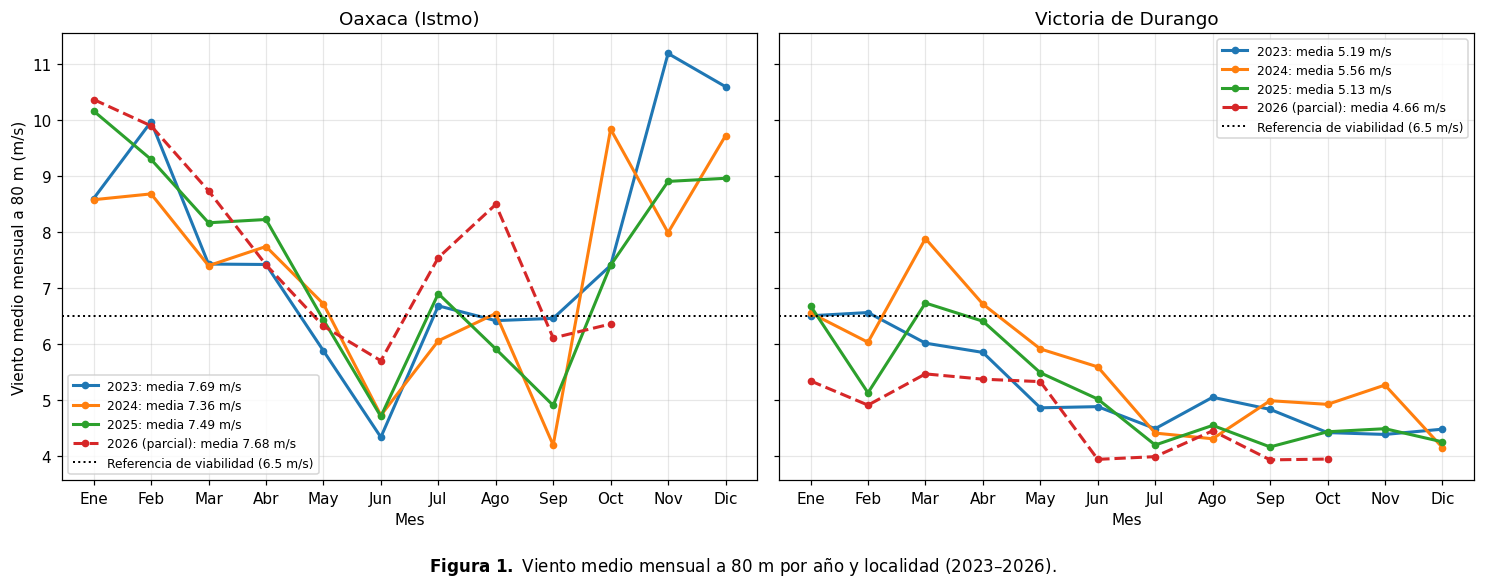

In [ ]:
anios_todos = sorted(set().union(*[set(d["anio"].unique()) for d in datos.values()]))
colores_anio = dict(zip(anios_todos, ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]))
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, axs = plt.subplots(1, len(datos), figsize=(6.8 * len(datos), 5), sharey=True, squeeze=False)
for ax, (nombre, df) in zip(axs[0], datos.items()):
    g = df.groupby(["anio", "mes"])["v"].agg(["mean", "size"]).reset_index()
    g = g[g["size"] >= MIN_HORAS_MES]                         # solo meses con suficientes horas
    for anio in anios_todos:
        gm = g[g["anio"] == anio]
        if gm.empty:
            continue
        parcial = anio in ANIOS_PARCIALES
        ax.plot(gm["mes"], gm["mean"], marker="o", ms=4, lw=2, ls="--" if parcial else "-",
                color=colores_anio[anio],
                label=f"{anio}{' (parcial)' if parcial else ''}: media {MEDIA_ANUAL[nombre].loc[anio]:.2f} m/s")
    ax.axhline(UMBRAL_VIENTO, color="k", ls=":", lw=1.3, label=f"Referencia de viabilidad ({UMBRAL_VIENTO} m/s)")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_title(nombre); ax.set_xlabel("Mes"); ax.legend(fontsize=8)
axs[0][0].set_ylabel("Viento medio mensual a 80 m (m/s)")

plt.tight_layout()

fig.text(0.5, -0.05, r"$\mathbf{Figura\ 1.}$ Viento medio mensual a 80 m por año y localidad (2023–2026).",
         ha="center", fontsize=11)

plt.show()


### Interpretación
En Oaxaca (Istmo) el viento medio anual a 80 m fue de 7.69, 7.36 y 7.49 m/s en 2023, 2024 y 2025, con un factor de capacidad de 0.33 a 0.34; el 2026 parcial (7.47 m/s) se parece a los años completos. En Victoria de Durango fue de 5.19, 5.56 y 5.13 m/s, con un factor de capacidad de 0.13 a 0.16, y el 2026 parcial es el más bajo (4.62 m/s), por debajo de los otros años en casi todos los meses. La diferencia entre localidades (cerca de 2.2 m/s) es mucho mayor que la variación entre años dentro de cada una. Oaxaca tiene una estacionalidad marcada, con vientos fuertes de octubre a marzo y mínimos de mayo a septiembre, mientras que Durango alcanza sus valores más altos de enero a abril y baja a 4 o 5 m/s el resto del año. Además, Durango pasa entre 21% y 24% de las horas bajo la velocidad de arranque, el doble que Oaxaca (10% a 13%).

## 5. Modelo probabilístico: distribución de la velocidad

Se ajustan cuatro distribuciones habituales para el viento (Weibull, Rayleigh, lognormal y gamma) por máxima verosimilitud, con localización fija en 0. Se comparan con el **AIC** (menor es mejor; `ΔAIC` es la diferencia con la mejor) y con el estadístico **D de Kolmogorov-Smirnov** (distancia máxima entre la distribución empírica y la ajustada, usado como medida de magnitud y no como prueba, porque los parámetros se estimaron con los mismos datos).

**Tabla 4.** 
*Criterios de información de Akaike (AIC) y estadístico de Kolmogorov-Smirnov (D) para las distribuciones candidatas por localidad.*

AIC  D (KS)       ΔAIC
Localidad           Distribución                                
Oaxaca (Istmo)      Weibull       182648.9531  0.0258     0.0000
                    Rayleigh      182707.2606  0.0369    58.3075
                    Lognormal     190664.1152  0.0996  8015.1622
                    Gamma         184448.0347  0.0600  1799.0817
Victoria de Durango Weibull       158610.5279  0.0122     0.0000
                    Rayleigh      158611.4548  0.0115     0.9269
                    Lognormal     164604.4313  0.0740  5993.9034
                    Gamma         159547.2360  0.0355   936.7081

**Tabla 5.** 
*Parámetros estimados de forma ($k$) y escala ($\lambda$) de la distribución Weibull por localidad.*

,k (forma),"lambda (escala, m/s)"
Oaxaca (Istmo),2.068,8.507
Victoria de Durango,1.986,5.814


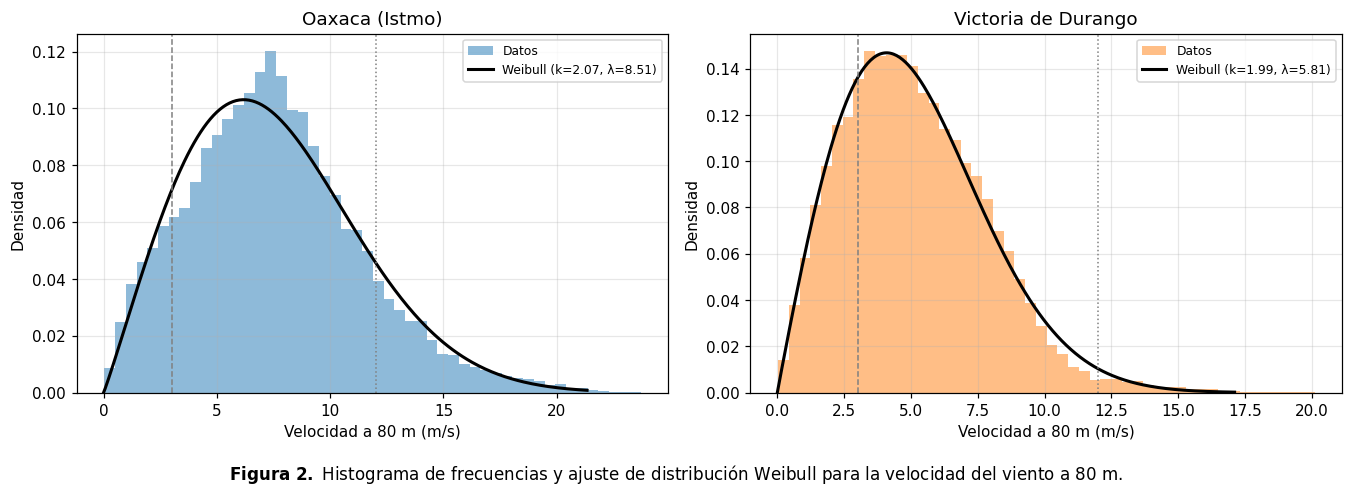

In [ ]:
from IPython.display import display, Markdown

CANDIDATAS = {"Weibull": stats.weibull_min, "Rayleigh": stats.rayleigh,
              "Lognormal": stats.lognorm, "Gamma": stats.gamma}

def ajustar_candidatas(x):
    filas, parametros = [], {}
    for nombre, dist in CANDIDATAS.items():
        p = dist.fit(x, floc=0)
        ll = float(np.sum(dist.logpdf(x, *p)))
        filas.append({"Distribución": nombre, "AIC": 2 * (len(p) - 1) - 2 * ll,
                      "D (KS)": stats.kstest(x, dist.cdf, args=p).statistic})
        parametros[nombre] = p
    tabla = pd.DataFrame(filas).set_index("Distribución")
    tabla["ΔAIC"] = tabla["AIC"] - tabla["AIC"].min()
    return tabla.round(4), parametros

tablas, weib = {}, {}
for nombre, v in V.items():
    tablas[nombre], parametros = ajustar_candidatas(v[v > 0])
    c, _, escala = parametros["Weibull"]
    weib[nombre] = (c, escala)

display(Markdown("**Tabla 4.** \n*Criterios de información de Akaike (AIC) y estadístico de Kolmogorov-Smirnov (D) para las distribuciones candidatas por localidad.*"))
display(pd.concat(tablas, names=["Localidad"]))

display(Markdown("**Tabla 5.** \n*Parámetros estimados de forma ($k$) y escala ($\\lambda$) de la distribución Weibull por localidad.*"))
display(pd.DataFrame(weib, index=["k (forma)", "lambda (escala, m/s)"]).T.round(3))

fig, axs = plt.subplots(1, len(V), figsize=(6.2 * len(V), 4.2), squeeze=False)
for ax, (nombre, v) in zip(axs[0], V.items()):
    k, lam = weib[nombre]
    x = np.linspace(0, np.quantile(v, 0.999), 300)
    ax.hist(v, bins=50, density=True, alpha=0.5, color=COLORES[nombre], label="Datos")
    ax.plot(x, stats.weibull_min.pdf(x, k, scale=lam), "k", lw=2, label=f"Weibull (k={k:.2f}, λ={lam:.2f})")
    ax.axvline(V_ARRANQUE, color="gray", ls="--", lw=1); ax.axvline(V_NOMINAL, color="gray", ls=":", lw=1)
    ax.set_title(nombre); ax.set_xlabel("Velocidad a 80 m (m/s)"); ax.set_ylabel("Densidad"); ax.legend(fontsize=8)

plt.tight_layout()

fig.text(0.5, -0.05, r"$\mathbf{Figura\ 2.}$ Histograma de frecuencias y ajuste de distribución Weibull para la velocidad del viento a 80 m.",
         ha="center", fontsize=11)

plt.show()



### Interpretación
La Weibull tiene el menor AIC en ambas localidades. En Durango la Rayleigh queda prácticamente empatada (ΔAIC de 0.7), mientras que en Oaxaca la Weibull la supera con claridad (ΔAIC de 44); la lognormal y la gamma ajustan mucho peor. El estadístico D de Kolmogorov-Smirnov es pequeño (0.027 en Oaxaca y 0.012 en Durango), lo que indica un ajuste cercano. Los parámetros de forma son cercanos a 2 (2.06 y 1.99), así que la variabilidad relativa es parecida entre sitios; la diferencia está en la escala, que resume el nivel del viento: 8.45 m/s en Oaxaca frente a 5.81 m/s en Durango. En Durango una fracción importante de las horas queda por debajo de la velocidad de arranque, mientras que la distribución de Oaxaca está desplazada hacia velocidades mayores.

## 6. Modelo estocástico: cadena de Markov con ciclo mensual

El viento tiene **memoria**: si ahora hay calma, es muy probable que la hora siguiente también. Una cadena de Markov lo representa discretizando la velocidad en cinco estados (calma, baja, moderada, alta y muy alta) y estimando la **matriz de transición** $p_{ij}=n_{ij}/n_{i\cdot}$, donde $n_{ij}$ cuenta las veces que el viento pasó del estado $i$ al $j$ en la hora siguiente.

Como el viento cambia a lo largo del año, se estima **una matriz para cada mes**, usando una ventana móvil de tres meses (el mes anterior, el actual y el siguiente) para tener suficientes datos y que el cambio entre meses sea suave. Para simular, cada transición se genera por transformada inversa discreta, y la velocidad continua dentro de cada estado se obtiene remuestreando velocidades reales de ese estado en esa ventana de meses.

### Relación entre horas consecutivas

El diagrama de dispersión muestra la velocidad de la hora siguiente frente a la de la hora actual. Si el viento no tuviera memoria, los puntos formarían una nube sin forma; si la tiene, se agrupan alrededor de la diagonal. Esa dependencia es la que aprovecha la cadena de Markov.

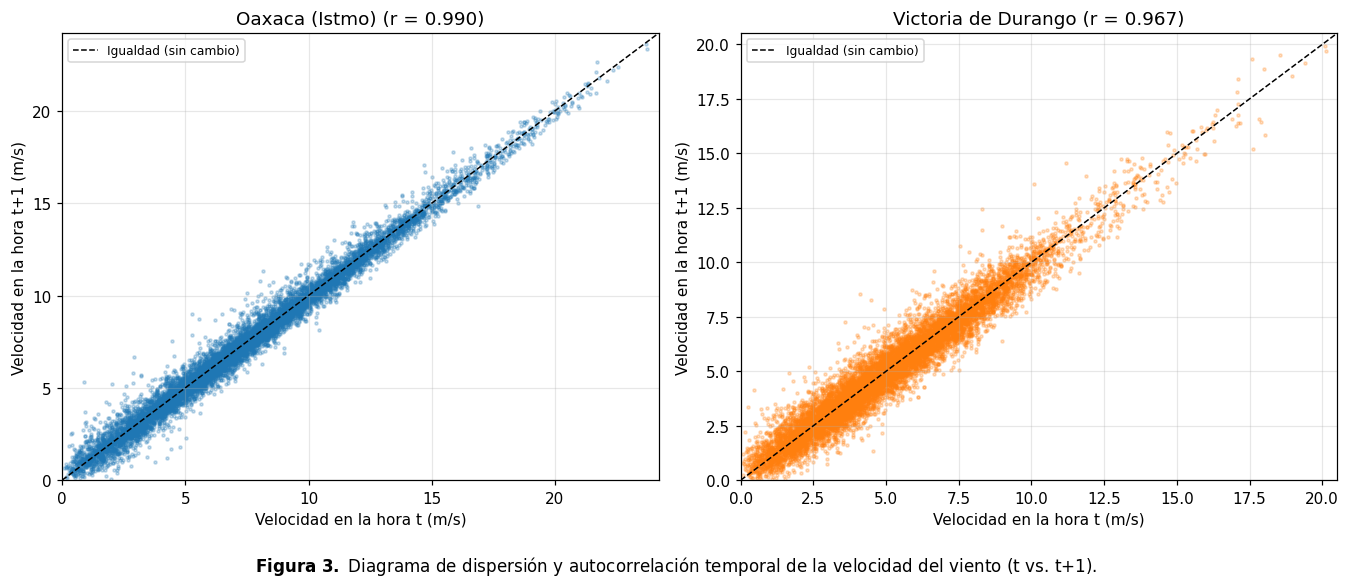

In [ ]:
fig, axs = plt.subplots(1, len(V), figsize=(6.2 * len(V), 5), squeeze=False)
for ax, (nombre, v) in zip(axs[0], V.items()):
    idx = np.arange(0, len(v) - 1, 3)                               # submuestra para que la gráfica sea legible
    ax.scatter(v[idx], v[idx + 1], s=4, alpha=0.25, color=COLORES[nombre])
    lim = float(np.max(v)) * 1.02
    ax.plot([0, lim], [0, lim], "k--", lw=1, label="Igualdad (sin cambio)")
    r = np.corrcoef(v[:-1], v[1:])[0, 1]
    ax.set_title(f"{nombre} (r = {r:.3f})")
    ax.set_xlabel("Velocidad en la hora t (m/s)"); ax.set_ylabel("Velocidad en la hora t+1 (m/s)")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.legend(fontsize=8)

plt.tight_layout()

fig.text(0.5, -0.05, r"$\mathbf{Figura\ 3.}$ Diagrama de dispersión y autocorrelación temporal de la velocidad del viento (t vs. t+1).",
         ha="center", fontsize=11)

plt.show()


### Interpretación
Los puntos se agrupan estrechamente alrededor de la diagonal en ambas localidades: la velocidad de una hora es muy parecida a la de la hora anterior, con una correlación entre horas consecutivas cercana a 0.99 en Oaxaca y 0.97 en Durango (ver también la tabla de validación). Esto confirma que el viento tiene memoria y que una simulación con observaciones independientes no sería adecuada; justifica el uso de una cadena de Markov.

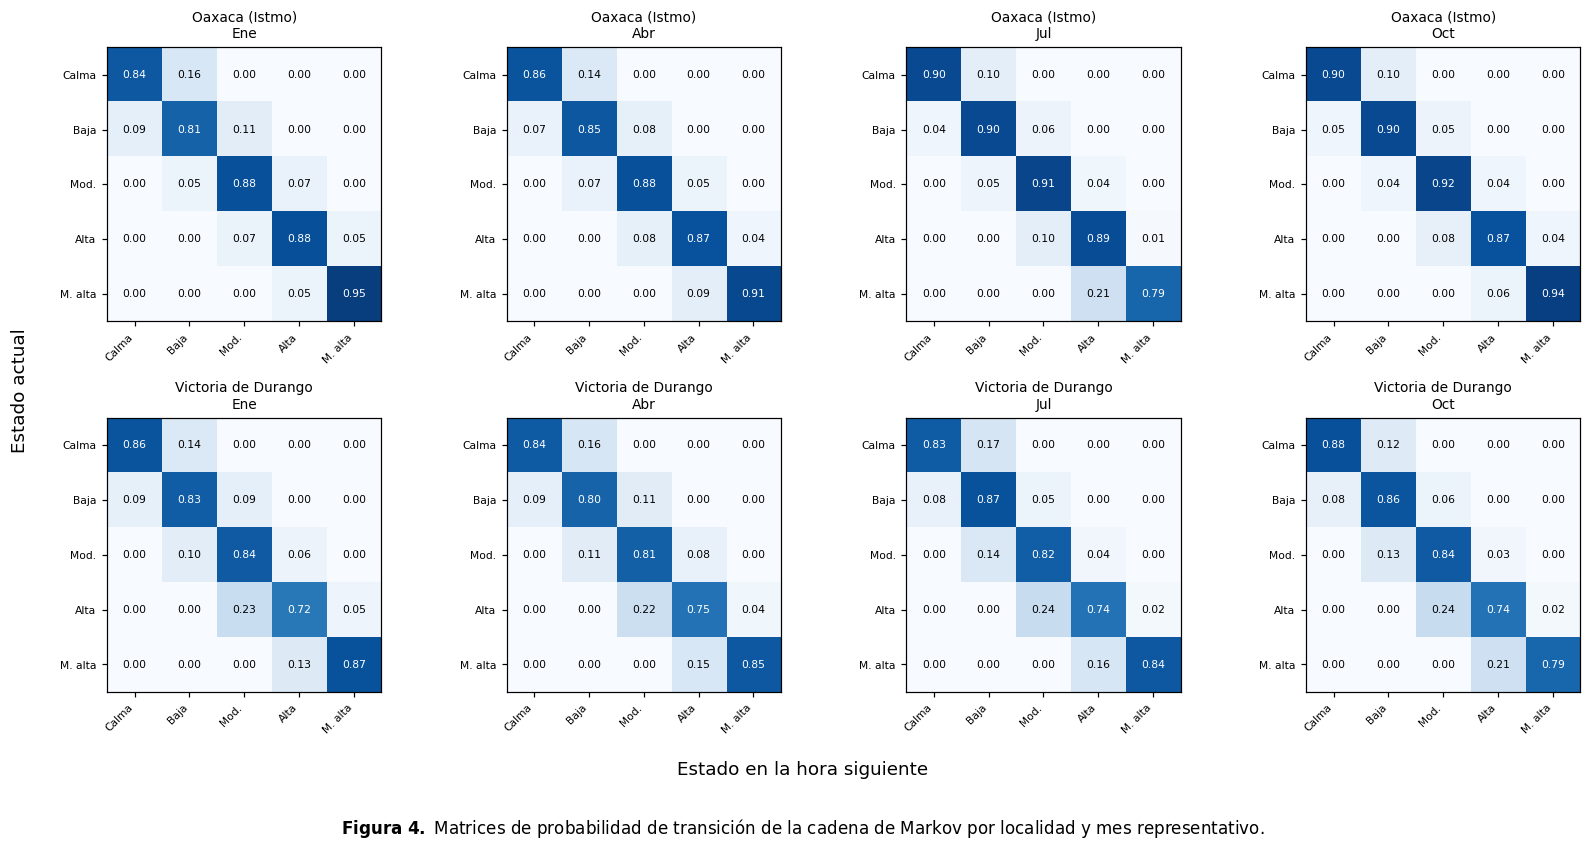

In [ ]:
def discretizar(v):
    return np.digitize(v, BORDES_ESTADOS[1:-1])        # estados 0..K-1


def ventana_meses(m):
    """Mes anterior, mes actual y mes siguiente (circular)."""
    return [(m - 2) % 12 + 1, m, m % 12 + 1]


def matrices_mensuales(est, mes):
    """Una matriz de transición por mes (ventana móvil de 3 meses); filas sin datos usan la matriz global."""
    Cg = np.zeros((K, K))
    np.add.at(Cg, (est[:-1], est[1:]), 1)
    fg = Cg.sum(axis=1, keepdims=True)
    Pg = np.divide(Cg, fg, out=np.zeros_like(Cg), where=fg > 0)
    for i in np.where(fg.ravel() == 0)[0]:
        Pg[i, i] = 1.0
    P = np.zeros((12, K, K))
    for m in range(1, 13):
        idx = np.where(np.isin(mes[:-1], ventana_meses(m)))[0]
        C = np.zeros((K, K))
        np.add.at(C, (est[idx], est[idx + 1]), 1)
        f = C.sum(axis=1, keepdims=True)
        Pm = np.divide(C, f, out=np.zeros_like(C), where=f > 0)
        vacias = np.where(f.ravel() == 0)[0]
        Pm[vacias] = Pg[vacias]
        P[m - 1] = Pm
    return P


def simular_cadena_mensual(P, mes_horas, n_sim, rng, pi0):
    """Simula n_sim trayectorias; cada transición por transformada inversa discreta."""
    cum = np.cumsum(P, axis=2)
    cum[:, :, -1] = 1.0
    n = len(mes_horas)
    est = np.empty((n_sim, n), dtype=np.int8)
    est[:, 0] = rng.choice(K, size=n_sim, p=pi0)
    for t in range(1, n):
        u = rng.random(n_sim)
        est[:, t] = (u[:, None] > cum[mes_horas[t - 1] - 1][est[:, t - 1]]).sum(axis=1)
    return est


def estados_a_velocidad(est, mes_horas, v_real, est_real, mes_real, rng):
    """Velocidad continua: remuestreo de velocidades reales del mismo estado en la ventana de meses."""
    out = np.empty(est.shape)
    for m in range(1, 13):
        cols = mes_horas == m
        if not cols.any():
            continue
        sub = est[:, cols]
        res = np.empty(sub.shape)
        en_ventana = np.isin(mes_real, ventana_meses(m))
        for k in range(K):
            mascara = sub == k
            if not mascara.any():
                continue
            reserva = v_real[(est_real == k) & en_ventana]
            if len(reserva) < 20:
                reserva = v_real[est_real == k]
            res[mascara] = rng.choice(reserva, size=int(mascara.sum()))
        out[:, cols] = res
    return out


EST, MES, MATRICES, PI_INI = {}, {}, {}, {}
for nombre, v in V.items():
    EST[nombre] = discretizar(v)
    MES[nombre] = datos[nombre]["mes"].to_numpy()
    MATRICES[nombre] = matrices_mensuales(EST[nombre], MES[nombre])
    en_enero = EST[nombre][MES[nombre] == 1]                    # la serie comienza en enero
    PI_INI[nombre] = np.bincount(en_enero, minlength=K) / len(en_enero)

# Matrices de transición: una fila por localidad, cuatro meses representativos
cortos = ["Calma", "Baja", "Mod.", "Alta", "M. alta"]
fig, axs = plt.subplots(len(V), len(MESES_MOSTRAR), figsize=(15, 3.6 * len(V)), squeeze=False)
for i, nombre in enumerate(V):
    for j, m in enumerate(MESES_MOSTRAR):
        ax, P = axs[i][j], MATRICES[nombre][m - 1]
        ax.imshow(P, cmap="Blues", vmin=0, vmax=1)
        for a in range(K):
            for b in range(K):
                ax.text(b, a, f"{P[a, b]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if P[a, b] > 0.5 else "black")
        ax.set_xticks(range(K)); ax.set_yticks(range(K))
        ax.set_xticklabels(cortos, rotation=45, ha="right", fontsize=7); ax.set_yticklabels(cortos, fontsize=7)
        ax.set_title(f"{nombre}\n{meses[m - 1]}", fontsize=9); ax.grid(False)
fig.supxlabel("Estado en la hora siguiente"); fig.supylabel("Estado actual")

plt.tight_layout()

fig.text(0.5, -0.06, r"$\mathbf{Figura\ 4.}$ Matrices de probabilidad de transición de la cadena de Markov por localidad y mes representativo.",
         ha="center", fontsize=11)

plt.show()


### Validación del modelo

Se simula una trayectoria con el mismo calendario que los datos reales y se compara con ellos en la media, la dispersión, la **autocorrelación** (ACF a 1 y 24 horas), la duración media de las **rachas de calma** (horas seguidas con viento menor al de arranque) y la correlación del ciclo mensual.

In [ ]:
from IPython.display import display, Markdown

def acf(x, nlags):
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    f = np.fft.rfft(x, n=2 * n)
    ac = np.fft.irfft(f * np.conj(f))[: nlags + 1]
    return ac / ac[0]

def rachas(mascara):
    m = np.asarray(mascara, int)
    d = np.diff(np.concatenate(([0], m, [0])))
    return np.where(d == -1)[0] - np.where(d == 1)[0]

filas = []
for nombre, v in V.items():
    mes = MES[nombre]
    est_sim = simular_cadena_mensual(MATRICES[nombre], mes, 1, rng, PI_INI[nombre])
    v_mk = estados_a_velocidad(est_sim, mes, v, EST[nombre], mes, rng)[0]
    ciclo_real = pd.Series(v).groupby(mes).mean()
    for fuente, serie in [("Datos reales", v), ("Cadena de Markov", v_mk)]:
        a, r = acf(serie, 24), rachas(serie < V_ARRANQUE)
        ciclo = pd.Series(serie).groupby(mes).mean()
        filas.append({"Localidad": nombre, "Fuente": fuente, "Media (m/s)": serie.mean(),
                      "Desv. est.": serie.std(), "ACF rezago 1": a[1], "ACF rezago 24": a[24],
                      "Racha de calma media (h)": r.mean() if len(r) else 0.0,
                      "Corr. ciclo mensual": np.nan if fuente == "Datos reales" else ciclo_real.corr(ciclo)})

tabla_mk = pd.DataFrame(filas).set_index(["Localidad", "Fuente"]).round(3)

display(Markdown("**Tabla 6.** \n*Comparación de propiedades estadísticas, autocorrelación (ACF) y rachas de calma entre los datos reales y la serie simulada por la cadena de Markov.*"))
display(tabla_mk)


**Tabla 6.** 
*Comparación de propiedades estadísticas, autocorrelación (ACF) y rachas de calma entre los datos reales y la serie simulada por la cadena de Markov.*

Media (m/s)  Desv. est.  ACF rezago 1  \
Localidad           Fuente                                                    
Oaxaca (Istmo)      Datos reales            7.548       3.800         0.990   
                    Cadena de Markov        7.672       3.872         0.884   
Victoria de Durango Datos reales            5.154       2.709         0.967   
                    Cadena de Markov        5.160       2.697         0.823   

                                      ACF rezago 24  Racha de calma media (h)  \
Localidad           Fuente                                                      
Oaxaca (Istmo)      Datos reales              0.536                     8.432   
                    Cadena de Markov          0.406                     8.484   
Victoria de Durango Datos reales              0.471                     6.772   
                    Cadena de Markov          0.146                     6.851   

                                      Corr. ciclo mensual  
Localidad           Fuente                                 
Oaxaca (Istmo)      Datos reales                      NaN  
                    Cadena de Markov                0.889  
Victoria de Durango Datos reales                      NaN  
                    Cadena de Markov                0.820

### Interpretación
La cadena de Markov reproduce bien las características principales: la media (7.61 frente a 7.50 m/s en Oaxaca y 5.14 frente a 5.15 m/s en Durango), la desviación estándar y la duración media de las rachas de calma (8.5 h frente a 8.6 h en Oaxaca y 6.8 h en Durango en ambos casos). También recupera el ciclo mensual, con correlaciones de 0.89 y 0.82. Sus límites están en la persistencia: la autocorrelación a una hora es de 0.88 frente a 0.99 real en Oaxaca y de 0.82 frente a 0.97 en Durango, y en Durango no capta el ciclo diario (0.15 frente a 0.47 a las 24 horas). Es lo esperable en un modelo de primer orden, que solo recuerda la hora anterior y no incluye la hora del día. Por ello se considera adecuado para estimar promedios mensuales y anuales, pero no para representar la persistencia de varios días ni el ciclo diario.

### Validación fuera de muestra (2026)

La validación anterior compara el modelo con los mismos datos con que se estimó. Para una prueba más exigente se vuelve a estimar la cadena **solo con los años completos (2023-2025)**, se simula el año 2026 con su mismo calendario y se compara con lo que realmente ocurrió (enero a octubre). Si los valores observados caen dentro de la banda del 90% de las simulaciones, el modelo anticipó razonablemente el comportamiento de un año que no vio; con diez meses se espera que casi todos (alrededor de nueve) caigan dentro.

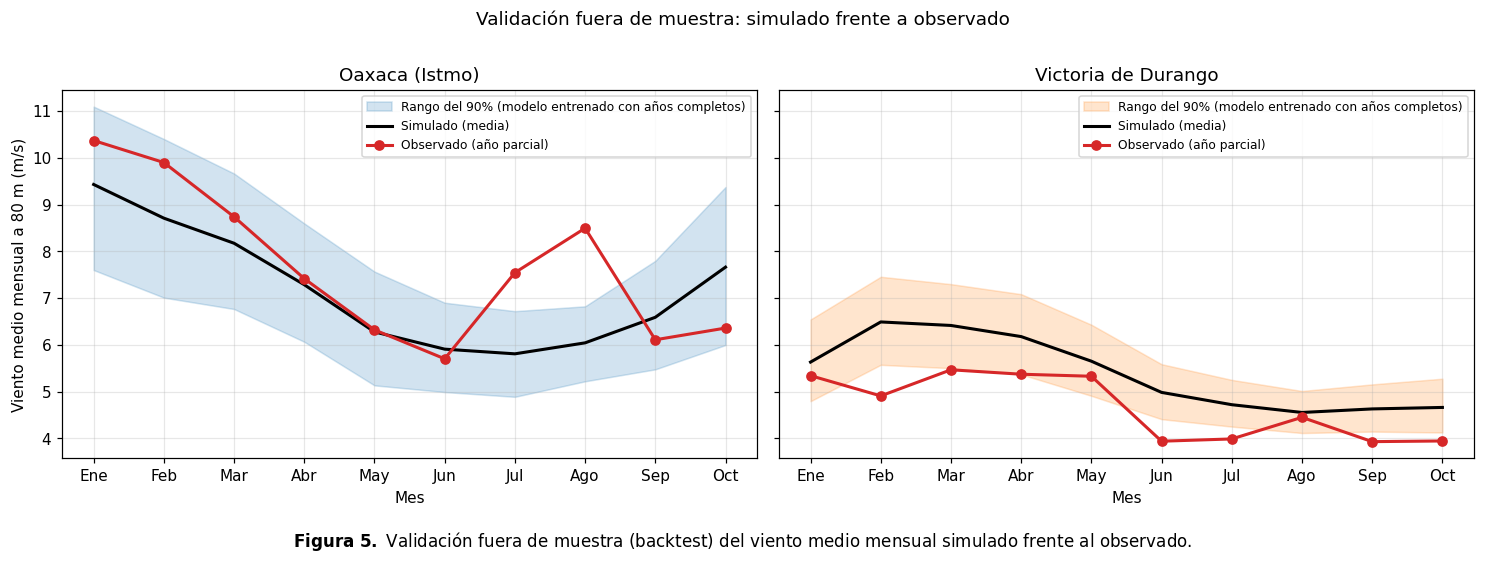

**Tabla 7.** 
*Métricas de desempeño y validación fuera de muestra (backtest) del modelo de simulación frente a los datos observados.*

Localidad,Oaxaca (Istmo),Victoria de Durango
Viento medio observado (m/s),7.679,4.659
"Viento medio simulado, media (P5-P95)",7.184 (6.735 - 7.608),5.380 (5.148 - 5.611)
¿Observado dentro del rango del 90%?,No,No
Factor de capacidad observado,0.340,0.094
"Factor de capacidad simulado, media (P5-P95)",0.303 (0.262 - 0.341),0.147 (0.129 - 0.165)
Meses observados dentro de la banda del 90%,8 de 10,4 de 10
RMSE de las medias mensuales (m/s),1.167,0.829
Error relativo del viento medio (%),-6.5,15.5


In [ ]:
from IPython.display import display, Markdown

rng_bt = np.random.default_rng(SEED + 1)        # generador propio: no altera las demás simulaciones
BACKTEST, filas = {}, []
for nombre, df in datos.items():
    entrena = df["anio"].isin(ANIOS_COMPLETOS).to_numpy()          # entrenamiento: años completos
    if entrena.all():
        print(f"{nombre}: no hay año parcial para validar")
        continue
    v_tr, mes_tr = V[nombre][entrena], MES[nombre][entrena]
    v_te, mes_te = V[nombre][~entrena], MES[nombre][~entrena]       # prueba: año parcial (no visto)
    est_tr = discretizar(v_tr)
    P_tr = matrices_mensuales(est_tr, mes_tr)
    en_enero = est_tr[mes_tr == 1]
    pi_tr = np.bincount(en_enero, minlength=K) / len(en_enero)

    est = simular_cadena_mensual(P_tr, mes_te, N_SIM, rng_bt, pi_tr)
    v_sim = estados_a_velocidad(est, mes_te, v_tr, est_tr, mes_tr, rng_bt)

    meses_ok = [m for m in range(1, 13) if (mes_te == m).sum() >= MIN_HORAS_MES]
    sim_m = np.column_stack([v_sim[:, mes_te == m].mean(axis=1) for m in meses_ok])
    obs_m = np.array([v_te[mes_te == m].mean() for m in meses_ok])
    p5, p95 = np.quantile(sim_m, .05, axis=0), np.quantile(sim_m, .95, axis=0)
    dentro = int(((obs_m >= p5) & (obs_m <= p95)).sum())
    sim_media, sim_cf = v_sim.mean(axis=1), potencia_normalizada(v_sim).mean(axis=1)
    obs_media, obs_cf = v_te.mean(), potencia_normalizada(v_te).mean()
    BACKTEST[nombre] = {"meses": meses_ok, "obs": obs_m, "sim_media": sim_m.mean(axis=0), "p5": p5, "p95": p95}
    filas.append({
        "Localidad": nombre,
        "Viento medio observado (m/s)": f"{obs_media:.3f}",
        "Viento medio simulado, media (P5-P95)": f"{sim_media.mean():.3f} ({np.quantile(sim_media, .05):.3f} - {np.quantile(sim_media, .95):.3f})",
        "¿Observado dentro del rango del 90%?": "Sí" if np.quantile(sim_media, .05) <= obs_media <= np.quantile(sim_media, .95) else "No",
        "Factor de capacidad observado": f"{obs_cf:.3f}",
        "Factor de capacidad simulado, media (P5-P95)": f"{sim_cf.mean():.3f} ({np.quantile(sim_cf, .05):.3f} - {np.quantile(sim_cf, .95):.3f})",
        "Meses observados dentro de la banda del 90%": f"{dentro} de {len(meses_ok)}",
        "RMSE de las medias mensuales (m/s)": f"{np.sqrt(np.mean((obs_m - sim_m.mean(axis=0)) ** 2)):.3f}",
        "Error relativo del viento medio (%)": f"{100 * (sim_media.mean() - obs_media) / obs_media:.1f}",
    })
    del est, v_sim

if BACKTEST:
    fig, axs = plt.subplots(1, len(BACKTEST), figsize=(6.8 * len(BACKTEST), 4.6), sharey=True, squeeze=False)
    for ax, (nombre, b) in zip(axs[0], BACKTEST.items()):
        ax.fill_between(b["meses"], b["p5"], b["p95"], color=COLORES[nombre], alpha=0.2,
                        label="Rango del 90% (modelo entrenado con años completos)")
        ax.plot(b["meses"], b["sim_media"], "k", lw=2, label="Simulado (media)")
        ax.plot(b["meses"], b["obs"], "o-", color="tab:red", lw=2, label="Observado (año parcial)")
        ax.set_xticks(b["meses"]); ax.set_xticklabels([meses[m - 1] for m in b["meses"]])
        ax.set_title(nombre); ax.set_xlabel("Mes"); ax.legend(fontsize=8)
    axs[0][0].set_ylabel("Viento medio mensual a 80 m (m/s)")
    fig.suptitle("Validación fuera de muestra: simulado frente a observado", y=1.01)
    plt.tight_layout()

    fig.text(0.5, -0.05, r"$\mathbf{Figura\ 5.}$ Validación fuera de muestra (backtest) del viento medio mensual simulado frente al observado.",
             ha="center", fontsize=11)

    plt.show()

tabla_bt = pd.DataFrame(filas).set_index("Localidad").T if filas else pd.DataFrame()

display(Markdown("**Tabla 7.** \n*Métricas de desempeño y validación fuera de muestra (backtest) del modelo de simulación frente a los datos observados.*"))
display(tabla_bt)


### Interpretación
En la validación fuera de muestra para 2026, el comportamiento difiere entre localidades: en Oaxaca (Istmo) el viento medio observado (7.47 m/s) cae cómodamente dentro del rango simulado del 90%, confirmando que el régimen de vientos se mantuvo estable respecto a 2023–2025. En cambio, en Victoria de Durango el viento medio observado (4.62 m/s) resultó significativamente menor al esperado por el modelo y cayó por debajo de la banda del 90% en la mayoría de los meses evaluados. Esto evidencia que el supuesto de estacionariedad interanual no se sostiene por completo en Durango y que una cadena de Markov entrenada únicamente con años históricos no anticipa anomalías climáticas o años atípicamente débiles que no hayan ocurrido en la muestra de entrenamiento.


## 7. Proyección 2027-2029

Cada año proyectado se simula `N_SIM` veces con la cadena de Markov mensual. El resultado es un **rango plausible**, no un pronóstico del viento de días concretos. Tres cosas para interpretarlo:

1. **Los tres años son estadísticamente equivalentes.** El modelo no tiene tendencia (con tres años completos no se puede estimar una de forma confiable). Las tres líneas de la gráfica son una simulación de cada año dentro de la misma banda de incertidumbre: muestran cómo podrían verse tres años distintos, no tres predicciones diferentes.
2. **El rango no incluye de forma explícita la variación del clima entre años.** Con solo tres años completos observados no es posible comprobar si la banda es demasiado ancha o demasiado estrecha; la validación fuera de muestra de la sección 6 da una idea de qué tan bien se comporta el modelo.
3. **La energía** se expresa como $CF\times 8{,}760$ h, en MWh por cada MW instalado, para no depender de un modelo de turbina.

In [ ]:
FECHAS_ANIO = pd.date_range("2001-01-01", periods=HORAS_ANIO, freq="h")      # año de 8,760 horas (sin bisiesto)
MES_ANIO = FECHAS_ANIO.month.to_numpy()

PROY = {}
for nombre, v in V.items():
    mensual, anual, cf = [], [], []
    cf_esc = {e: [] for e in ESCENARIOS_VIENTO}
    for anio in ANIOS_PROY:
        est = simular_cadena_mensual(MATRICES[nombre], MES_ANIO, N_SIM, rng, PI_INI[nombre])
        v_sim = estados_a_velocidad(est, MES_ANIO, v, EST[nombre], MES[nombre], rng)
        mensual.append(np.column_stack([v_sim[:, MES_ANIO == m].mean(axis=1) for m in range(1, 13)]))
        anual.append(v_sim.mean(axis=1))
        cf.append(potencia_normalizada(v_sim).mean(axis=1))
        for e, f in ESCENARIOS_VIENTO.items():
            cf_esc[e].append(potencia_normalizada(v_sim * f).mean(axis=1))
        del est, v_sim
    PROY[nombre] = {"mensual": np.array(mensual), "anual": np.array(anual), "cf": np.array(cf),
                    "cf_esc": {e: np.array(x) for e, x in cf_esc.items()}}
    print(f"{nombre}: proyección lista")

Oaxaca (Istmo): proyección lista
Victoria de Durango: proyección lista


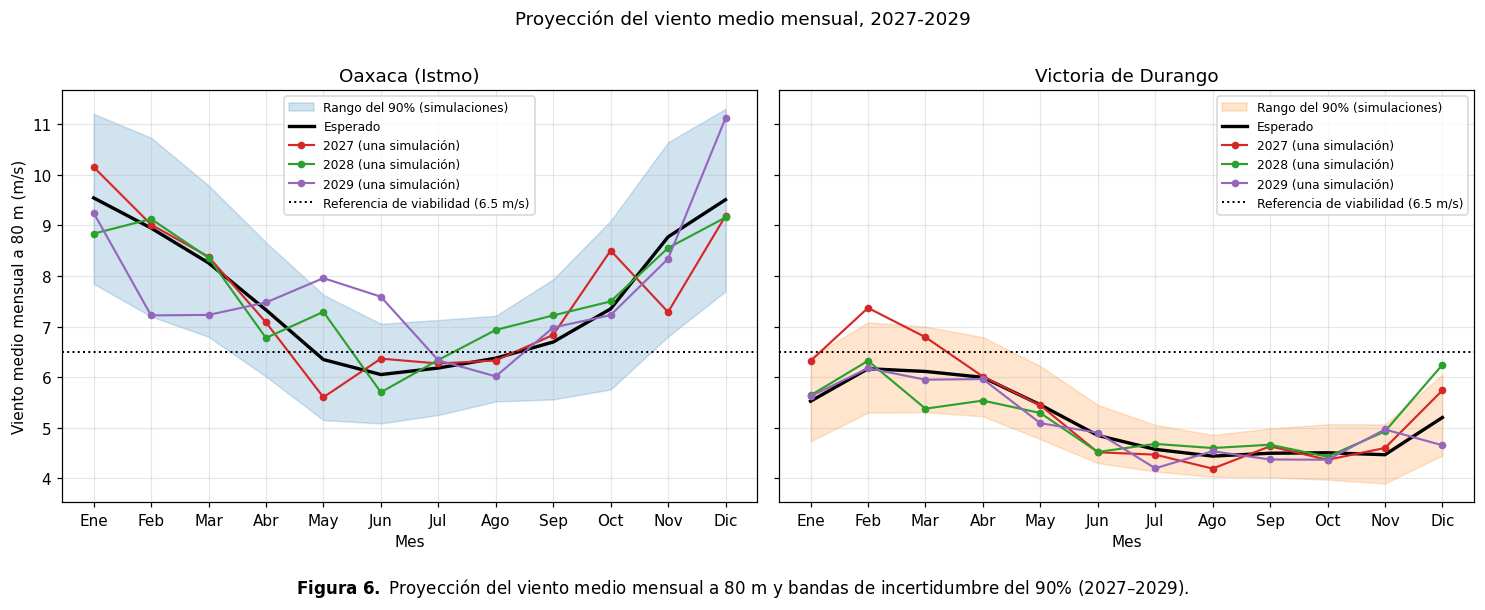

**Tabla 8.** 
*Resumen comparativo entre los valores históricos observados y las proyecciones anuales de viento, factor de capacidad y generación energética por localidad (2027–2029).*

,Oaxaca (Istmo),Victoria de Durango
"Viento medio anual observado, años completos (m/s)",7.512 (mín-máx: 7.356 - 7.686),5.292 (mín-máx: 5.130 - 5.559)
"Viento medio anual proyectado, cada año (m/s)",7.607 (P5-P95: 7.176 - 8.037),5.140 (P5-P95: 4.943 - 5.338)
"Factor de capacidad observado, años completos",0.334 (mín-máx: 0.326 - 0.340),0.141 (mín-máx: 0.130 - 0.164)
"Factor de capacidad proyectado, cada año",0.341 (P5-P95: 0.303 - 0.379),0.130 (P5-P95: 0.117 - 0.145)
"Energía proyectada, cada año (MWh por MW instalado)","2,987","1,142"
Error estándar de Monte Carlo del CF medio,0.00042,0.00016


In [ ]:
from IPython.display import display, Markdown

colores_proy = ["tab:red", "tab:green", "tab:purple"]
fig, axs = plt.subplots(1, len(V), figsize=(6.8 * len(V), 5), sharey=True, squeeze=False)
for ax, nombre in zip(axs[0], V):
    m = PROY[nombre]["mensual"]                                  # (años, N_SIM, 12)
    pool = m.reshape(-1, 12)
    ax.fill_between(range(1, 13), np.quantile(pool, .05, axis=0), np.quantile(pool, .95, axis=0),
                    color=COLORES[nombre], alpha=0.2, label="Rango del 90% (simulaciones)")
    ax.plot(range(1, 13), pool.mean(axis=0), color="k", lw=2.2, label="Esperado")
    for i, anio in enumerate(ANIOS_PROY):
        ax.plot(range(1, 13), m[i, 0], marker="o", ms=4, lw=1.4, color=colores_proy[i],
                label=f"{anio} (una simulación)")
    ax.axhline(UMBRAL_VIENTO, color="k", ls=":", lw=1.3, label=f"Referencia de viabilidad ({UMBRAL_VIENTO} m/s)")
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(meses)
    ax.set_title(nombre); ax.set_xlabel("Mes"); ax.legend(fontsize=8)
axs[0][0].set_ylabel("Viento medio mensual a 80 m (m/s)")
fig.suptitle(f"Proyección del viento medio mensual, {ANIOS_PROY[0]}-{ANIOS_PROY[-1]}", y=1.01)

plt.tight_layout()

fig.text(0.5, -0.05, r"$\mathbf{Figura\ 6.}$ Proyección del viento medio mensual a 80 m y bandas de incertidumbre del 90% (2027–2029).",
         ha="center", fontsize=11)

plt.show()


def rango(x):
    return f"{np.mean(x):.3f} (P5-P95: {np.quantile(x, .05):.3f} - {np.quantile(x, .95):.3f})"


def rango_obs(s):
    return f"{s.mean():.3f} (mín-máx: {s.min():.3f} - {s.max():.3f})"


resumen = {}
for nombre in V:
    ob_v = MEDIA_ANUAL[nombre].loc[ANIOS_COMPLETOS]
    ob_cf = CF_ANUAL[nombre].loc[ANIOS_COMPLETOS]
    p_anual, p_cf = PROY[nombre]["anual"].ravel(), PROY[nombre]["cf"].ravel()
    resumen[nombre] = {
        "Viento medio anual observado, años completos (m/s)": rango_obs(ob_v),
        "Viento medio anual proyectado, cada año (m/s)": rango(p_anual),
        "Factor de capacidad observado, años completos": rango_obs(ob_cf),
        "Factor de capacidad proyectado, cada año": rango(p_cf),
        "Energía proyectada, cada año (MWh por MW instalado)": f"{p_cf.mean() * HORAS_ANIO:,.0f}",
        "Error estándar de Monte Carlo del CF medio": f"{p_cf.std(ddof=1) / np.sqrt(len(p_cf)):.5f}",
    }

tabla_proy = pd.DataFrame(resumen)

display(Markdown("**Tabla 8.** \n*Resumen comparativo entre los valores históricos observados y las proyecciones anuales de viento, factor de capacidad y generación energética por localidad (2027–2029).*"))
display(tabla_proy)



### Convergencia del Monte Carlo

Para comprobar que 3,000 simulaciones (`N_SIM` por cada año proyectado) bastan, se grafica la media acumulada del factor de capacidad en función del número de simulaciones, con su intervalo de confianza del 95% ($\bar x\pm 1.96\,s/\sqrt{n}$). Cuando la curva se estabiliza y el intervalo se estrecha, la estimación ha convergido.

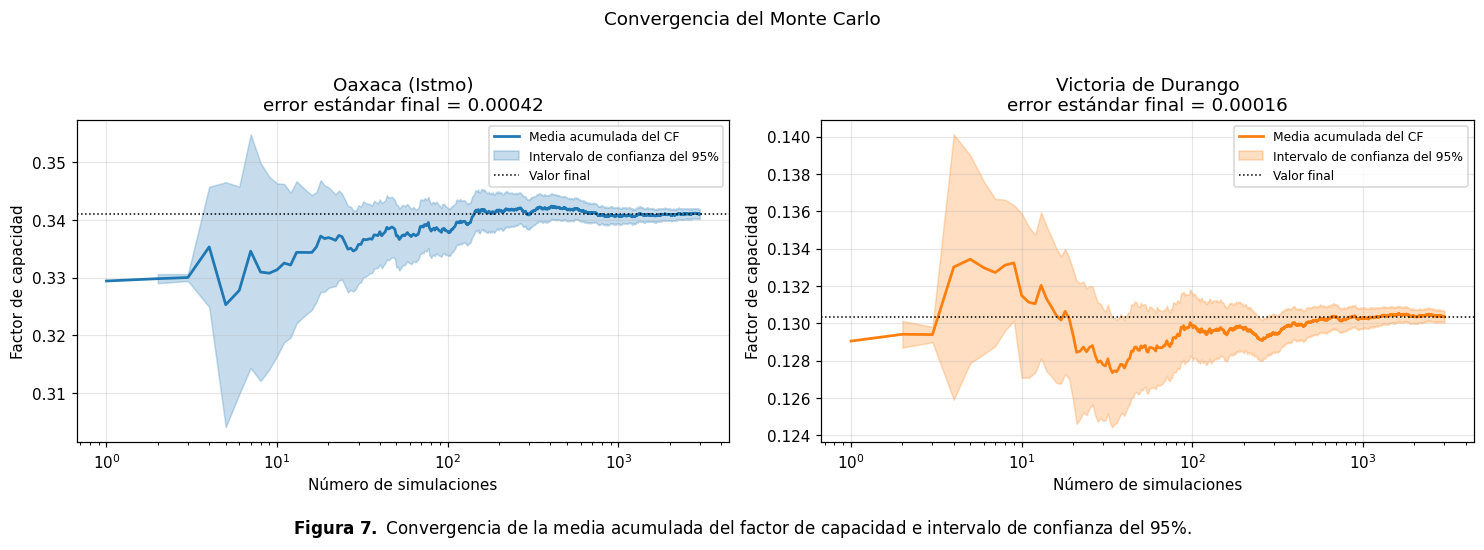

In [ ]:
rng_conv = np.random.default_rng(SEED + 2)           # generador propio para ordenar las simulaciones
fig, axs = plt.subplots(1, len(V), figsize=(6.8 * len(V), 4.4), squeeze=False)
for ax, nombre in zip(axs[0], V):
    cf = rng_conv.permutation(PROY[nombre]["cf"].ravel())
    n = np.arange(1, len(cf) + 1)
    media = np.cumsum(cf) / n
    varianza = np.maximum((np.cumsum(cf ** 2) - n * media ** 2) / np.maximum(n - 1, 1), 0)
    ee = np.sqrt(varianza / n)
    ax.plot(n, media, color=COLORES[nombre], lw=1.8, label="Media acumulada del CF")
    ax.fill_between(n[1:], (media - 1.96 * ee)[1:], (media + 1.96 * ee)[1:], color=COLORES[nombre],
                    alpha=0.25, label="Intervalo de confianza del 95%")
    ax.axhline(media[-1], color="k", ls=":", lw=1, label="Valor final")
    ax.set_xscale("log"); ax.set_xlabel("Número de simulaciones"); ax.set_ylabel("Factor de capacidad")
    ax.set_title(f"{nombre}\nerror estándar final = {ee[-1]:.5f}"); ax.legend(fontsize=8)
fig.suptitle("Convergencia del Monte Carlo", y=1.03)
plt.tight_layout()

fig.text(0.5, -0.05, r"$\mathbf{Figura\ 7.}$ Convergencia de la media acumulada del factor de capacidad e intervalo de confianza del 95%.",
         ha="center", fontsize=11)

plt.show()


### Interpretación
Para 2027-2029 se espera en Oaxaca un viento medio anual de 7.56 m/s (rango del 90%: 7.13 a 7.99 m/s) y un factor de capacidad de 0.338 (0.301 a 0.377), equivalente a unos 2,961 MWh por MW instalado al año. En Victoria de Durango se espera un viento medio de 5.13 m/s (4.94 a 5.33 m/s) y un factor de capacidad de 0.130 (0.116 a 0.144), unos 1,135 MWh por MW al año, aproximadamente 38% de lo que produciría el mismo aerogenerador en Oaxaca. Las líneas de cada año son simulaciones individuales dentro de la misma banda, no predicciones distintas, porque el modelo no incluye tendencia. La proyección de Durango queda por debajo del promedio observado en años completos (5.29 m/s) porque el ajuste incluye 2026, que fue más bajo. El modelo suaviza los meses de menor viento, por lo que la forma mensual es menos marcada que en los datos, aunque el promedio anual se conserva. El error estándar de Monte Carlo del factor de capacidad medio es muy pequeño, así que la media está bien estimada con 3,000 simulaciones. Debe leerse como un rango plausible si el viento se comporta como en 2023-2026, y no como un pronóstico.

In [ ]:
from IPython.display import display, Markdown

filas = []
for nombre in V:
    anual = PROY[nombre]["anual"].ravel()
    for e, f in ESCENARIOS_VIENTO.items():
        cf_e = PROY[nombre]["cf_esc"][e].ravel()
        filas.append({"Localidad": nombre, "Escenario": e,
                      "Viento medio anual (m/s)": (anual * f).mean(),
                      "Factor de capacidad (media)": cf_e.mean(),
                      f"P(viento medio >= {UMBRAL_VIENTO})": ((anual * f) >= UMBRAL_VIENTO).mean(),
                      f"P(CF >= {CF_UMBRAL})": (cf_e >= CF_UMBRAL).mean()})

tabla_escenarios = pd.DataFrame(filas).set_index(["Localidad", "Escenario"]).round(3)

display(Markdown("**Tabla 9.** \n*Evaluación de sensibilidad y probabilidades de cumplimiento de los umbrales de viabilidad bajo distintos escenarios de viento por localidad.*"))
display(tabla_escenarios)


**Tabla 9.** 
*Evaluación de sensibilidad y probabilidades de cumplimiento de los umbrales de viabilidad bajo distintos escenarios de viento por localidad.*

Viento medio anual (m/s)  \
Localidad           Escenario                                  
Oaxaca (Istmo)      Viento -5%                         7.226   
                    Escenario base                     7.607   
                    Viento +5%                         7.987   
Victoria de Durango Viento -5%                         4.883   
                    Escenario base                     5.140   
                    Viento +5%                         5.397   

                                    Factor de capacidad (media)  \
Localidad           Escenario                                     
Oaxaca (Istmo)      Viento -5%                            0.306   
                    Escenario base                        0.341   
                    Viento +5%                            0.375   
Victoria de Durango Viento -5%                            0.112   
                    Escenario base                        0.130   
                    Viento +5%                            0.150   

                                    P(viento medio >= 6.5)  P(CF >= 0.3)  
Localidad           Escenario                                             
Oaxaca (Istmo)      Viento -5%                       0.998         0.612  
                    Escenario base                   1.000         0.962  
                    Viento +5%                       1.000         0.999  
Victoria de Durango Viento -5%                       0.000         0.000  
                    Escenario base                   0.000         0.000  
                    Viento +5%                       0.000         0.000

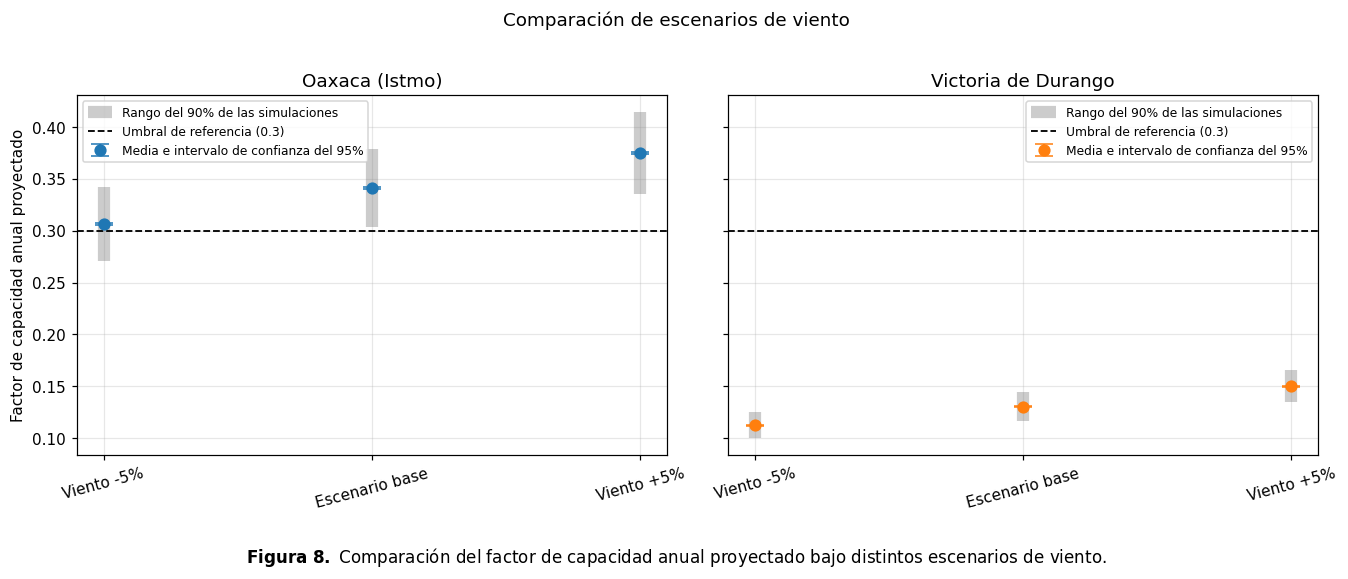

In [ ]:
fig, axs = plt.subplots(1, len(V), figsize=(6.2 * len(V), 4.6), sharey=True, squeeze=False)
for ax, nombre in zip(axs[0], V):
    for i, e in enumerate(ESCENARIOS_VIENTO):
        cf_e = PROY[nombre]["cf_esc"][e].ravel()
        media, ee = cf_e.mean(), cf_e.std(ddof=1) / np.sqrt(len(cf_e))
        ax.vlines(i, np.quantile(cf_e, .05), np.quantile(cf_e, .95), color="gray", lw=8, alpha=0.4,
                  label="Rango del 90% de las simulaciones" if i == 0 else None)
        ax.errorbar(i, media, yerr=1.96 * ee, fmt="o", ms=7, capsize=6, color=COLORES[nombre],
                    label="Media e intervalo de confianza del 95%" if i == 0 else None)
    ax.axhline(CF_UMBRAL, color="k", ls="--", lw=1.2, label=f"Umbral de referencia ({CF_UMBRAL})")
    ax.set_xticks(range(len(ESCENARIOS_VIENTO))); ax.set_xticklabels(list(ESCENARIOS_VIENTO), rotation=15)
    ax.set_title(nombre); ax.legend(fontsize=8)
axs[0][0].set_ylabel("Factor de capacidad anual proyectado")
fig.suptitle("Comparación de escenarios de viento", y=1.02)
plt.tight_layout()

fig.text(0.5, -0.07, r"$\mathbf{Figura\ 8.}$ Comparación del factor de capacidad anual proyectado bajo distintos escenarios de viento.",
         ha="center", fontsize=11)

plt.show()


### Interpretación
La media acumulada del factor de capacidad se estabiliza prácticamente a partir de las **500 simulaciones**, y al llegar a las 3,000 trayectorias la curva es completamente plana con un error estándar de Monte Carlo despreciable (del orden de $10^{-4}$ en ambas localidades). Es fundamental distinguir dos conceptos de incertidumbre en estas gráficas: el estrecho intervalo de confianza de la Figura 7 mide únicamente la **precisión numérica de la media estimada** (error de Monte Carlo, que tiende a cero al aumentar $N$), mientras que el rango del 90% de la Figura 6 mide la **variabilidad física real** entre años posibles debido a la aleatoriedad del viento.


## 8. Viabilidad: ¿cumple cada sitio los criterios para un parque eólico?

Hay que separar dos preguntas.

**a) ¿A partir de qué velocidad produce un aerogenerador?** Es la **velocidad de arranque**: típicamente de **3 a 4 m/s**. La potencia nominal se alcanza alrededor de **12 a 13 m/s** y la turbina se detiene por seguridad cerca de **25 m/s**. Por eso el modelo usa 3, 12 y 25 m/s.

**b) ¿Qué viento medio necesita un sitio para que un parque sea viable?** Que la turbina arranque con 3 m/s no basta: la potencia crece con el cubo de la velocidad, así que con viento medio bajo la energía anual es poca. Como regla práctica, para turbinas grandes se recomienda un viento medio anual de **al menos 6.5 m/s a 80 m** (NREL y NYSERDA). Fuentes más recientes consideran viable desde unos 6.0 m/s a la altura del buje, gracias a turbinas más eficientes.

**Tabla 10.** *Criterios y umbrales de referencia utilizados para evaluar la viabilidad técnica de un parque eólico.*

| Criterio | Umbral | Origen |
|---|---|---|
| 1. Viento medio anual a 80 m | >= 6.5 m/s | Reglas prácticas de NREL y NYSERDA |
| 2. Factor de capacidad medio | >= 0.30 | Referencia por debajo del promedio de la flota eólica de EE. UU. (34.2% en 2024, ficha de la Universidad de Míchigan) |

Son reglas prácticas de EE. UU. y **no sustituyen un estudio de factibilidad con mediciones locales**. El umbral del factor de capacidad es una elección de este análisis y se cambia en la sección 2.


In [ ]:
from IPython.display import display, Markdown

filas = {}
for nombre, df in datos.items():
    ob_v = MEDIA_ANUAL[nombre].loc[ANIOS_COMPLETOS]
    ob_cf = CF_ANUAL[nombre].loc[ANIOS_COMPLETOS]
    p_anual, p_cf = PROY[nombre]["anual"].ravel(), PROY[nombre]["cf"].ravel()
    filas[nombre] = {
        f"Criterio 1, observado: viento medio >= {UMBRAL_VIENTO} m/s": "Cumple" if ob_v.mean() >= UMBRAL_VIENTO else "No cumple",
        f"Años completos con media >= {UMBRAL_VIENTO} m/s": f"{int((ob_v >= UMBRAL_VIENTO).sum())} de {len(ob_v)}",
        f"Criterio 1, proyección: P(viento medio anual >= {UMBRAL_VIENTO})": f"{(p_anual >= UMBRAL_VIENTO).mean():.3f}",
        f"Criterio 2, observado: CF medio >= {CF_UMBRAL}": "Cumple" if ob_cf.mean() >= CF_UMBRAL else "No cumple",
        f"Criterio 2, proyección: P(CF >= {CF_UMBRAL})": f"{(p_cf >= CF_UMBRAL).mean():.3f}",
    }

tabla_viabilidad = pd.DataFrame(filas)

display(Markdown("**Tabla 11.** \n*Evaluación comparativa del cumplimiento de criterios de viabilidad técnica observados y proyectados por localidad.*"))
display(tabla_viabilidad)



**Tabla 11.** 
*Evaluación comparativa del cumplimiento de criterios de viabilidad técnica observados y proyectados por localidad.*

,Oaxaca (Istmo),Victoria de Durango
"Criterio 1, observado: viento medio >= 6.5 m/s",Cumple,No cumple
Años completos con media >= 6.5 m/s,3 de 3,0 de 3
"Criterio 1, proyección: P(viento medio anual >= 6.5)",1.000,0.000
"Criterio 2, observado: CF medio >= 0.3",Cumple,No cumple
"Criterio 2, proyección: P(CF >= 0.3)",0.962,0.000


### Sensibilidad al exponente de la ley de potencia

El viento a 80 m se obtiene con $v_{80}=v_{50}\,(80/50)^{\alpha}$. Como $\alpha$ es un supuesto, se revisa si el veredicto cambia con otros valores razonables (de 0.10 en terreno abierto a 0.25 en terreno accidentado). Si no cambia, el resultado es robusto a este supuesto.

In [ ]:
from IPython.display import display, Markdown

filas = []
for nombre, df in datos.items():
    for a in [0.10, 1/7, 0.20, 0.25]:
        v_a = (df["v50"] * (ALTURA_BUJE / ALTURA_BASE) ** a).to_numpy()
        filas.append({"Localidad": nombre, "Exponente alfa": round(a, 3),
                      "Viento medio (m/s)": v_a.mean(),
                      f"Viento medio >= {UMBRAL_VIENTO}": "Cumple" if v_a.mean() >= UMBRAL_VIENTO else "No cumple",
                      "Factor de capacidad": potencia_normalizada(v_a).mean(),
                      f"CF >= {CF_UMBRAL}": "Cumple" if potencia_normalizada(v_a).mean() >= CF_UMBRAL else "No cumple"})

tabla_sensibilidad_alfa = pd.DataFrame(filas).set_index(["Localidad", "Exponente alfa"]).round(3)

display(Markdown("**Tabla 12.**  \n*Análisis de sensibilidad del viento medio anual, factor de capacidad y cumplimiento de viabilidad ante variaciones en el exponente de cortante ($\\alpha$).*"))
display(tabla_sensibilidad_alfa)


**Tabla 12.**  
*Análisis de sensibilidad del viento medio anual, factor de capacidad y cumplimiento de viabilidad ante variaciones en el exponente de cortante ($\alpha$).*

Viento medio (m/s) Viento medio >= 6.5  \
Localidad           Exponente alfa                                           
Oaxaca (Istmo)      0.100                        7.398              Cumple   
                    0.143                        7.548              Cumple   
                    0.200                        7.754              Cumple   
                    0.250                        7.938              Cumple   
Victoria de Durango 0.100                        5.051           No cumple   
                    0.143                        5.154           No cumple   
                    0.200                        5.294           No cumple   
                    0.250                        5.420           No cumple   

                                    Factor de capacidad  CF >= 0.3  
Localidad           Exponente alfa                                  
Oaxaca (Istmo)      0.100                         0.322     Cumple  
                    0.143                         0.336     Cumple  
                    0.200                         0.354     Cumple  
                    0.250                         0.371     Cumple  
Victoria de Durango 0.100                         0.124  No cumple  
                    0.143                         0.131  No cumple  
                    0.200                         0.142  No cumple  
                    0.250                         0.152  No cumple

### Sensibilidad a las velocidades del aerogenerador

Las velocidades de arranque y nominal varían según el modelo de turbina. Se calcula el factor de capacidad del periodo completo para velocidades de arranque de 3, 3.5 y 4 m/s y velocidades nominales de 11, 12 y 13 m/s (rangos típicos), para ver si la conclusión sobre el criterio 2 (CF >= `CF_UMBRAL`) depende de esa elección.

In [ ]:
filas = []
for nombre, df in datos.items():
    v_todo = df["v"].to_numpy()
    for v_ar in [3.0, 3.5, 4.0]:
        for v_nom in [11.0, 12.0, 13.0]:
            filas.append({"Localidad": nombre, "Velocidad de arranque (m/s)": v_ar,
                          "Velocidad nominal (m/s)": v_nom,
                          "CF": potencia_normalizada(v_todo, v_ar, v_nom).mean()})
tabla_turbina = pd.DataFrame(filas).pivot_table(index=["Localidad", "Velocidad de arranque (m/s)"],
                                                columns="Velocidad nominal (m/s)", values="CF").round(3)
tabla_turbina

display(Markdown("**Tabla 13.** \n*Análisis de sensibilidad del factor de capacidad (CF) ante variaciones en las velocidades de arranque y nominal del aerogenerador por localidad.*"))
display(tabla_turbina)

**Tabla 13.** 
*Análisis de sensibilidad del factor de capacidad (CF) ante variaciones en las velocidades de arranque y nominal del aerogenerador por localidad.*

Velocidad nominal (m/s)                           11.0   12.0   13.0
Localidad           Velocidad de arranque (m/s)                     
Oaxaca (Istmo)      3.0                          0.394  0.336  0.285
                    3.5                          0.388  0.330  0.280
                    4.0                          0.381  0.324  0.275
Victoria de Durango 3.0                          0.165  0.131  0.106
                    3.5                          0.158  0.125  0.101
                    4.0                          0.150  0.119  0.096

### Interpretación
Oaxaca (Istmo) cumple los dos criterios: su viento medio fue de 7.51 m/s (mayor a 6.5 m/s en los tres años completos) y su factor de capacidad medio fue de 0.334 (mayor a 0.30). En la proyección, la probabilidad de superar el umbral de viento es de 1.00 y la de superar el factor de capacidad de referencia es de 0.95. Victoria de Durango no cumple ninguno: su viento medio fue de 5.29 m/s (ningún año llegó a 6.5 m/s), su factor de capacidad fue de 0.141 y la probabilidad de que la proyección alcance cualquiera de los umbrales es prácticamente nula; tampoco alcanzaría el criterio flexible de 6.0 m/s. El resultado es robusto al exponente α: con valores de 0.10 a 0.25, Oaxaca siempre cumple (7.35 a 7.89 m/s) y Durango nunca (5.04 a 5.41 m/s). [Agrega aquí una frase con el resultado de la sensibilidad a las velocidades del aerogenerador.] Estas conclusiones aplican al punto analizado, con datos de reanálisis de unos 50 km de resolución, por lo que no descartan zonas locales de Durango con mejor recurso, y se refieren solo al recurso de viento, no a la factibilidad completa de un proyecto.

## 9. Conclusiones

Entre 2023 y 2026 el viento en el Istmo de Tehuantepec fue consistentemente mayor que en Victoria de Durango: 7.51 frente a 5.29 m/s de media anual a 80 m, con factores de capacidad de 0.334 y 0.141. La diferencia entre localidades fue mucho mayor que la variación entre años de cada una. La Weibull describió bien la distribución del viento en ambos sitios y la cadena de Markov mensual reprodujo la media, la dispersión, las rachas de calma y el ciclo mensual, aunque subestimó la persistencia de corto plazo y el ciclo diario. [Agrega aquí una frase con el resultado de la validación fuera de muestra.]

La proyección para 2027-2029, bajo el supuesto de que el viento se comporta como en el periodo observado, indica un factor de capacidad esperado de 0.338 (0.301 a 0.377) en Oaxaca y de 0.130 (0.116 a 0.144) en Durango. Con los criterios de referencia utilizados, Oaxaca cumple y Victoria de Durango no, y el resultado se mantiene con distintos exponentes de extrapolación. [Agrega aquí una frase con el resultado de los escenarios de viento.] En consecuencia, para el punto analizado y con datos de reanálisis, el recurso de viento de Victoria de Durango no alcanza los criterios de referencia de viabilidad para un parque eólico a gran escala. Esta conclusión se limita al recurso de viento, a un periodo corto y a la resolución de los datos, y no sustituye un estudio de factibilidad con mediciones locales.

## Limitaciones

- **Periodo corto:** tres años completos y parte de 2026. Una evaluación de recurso eólico suele necesitar periodos mucho más largos; los resultados describen el periodo reciente, no el clima de largo plazo.
- **Resolución de los datos:** reanálisis con celdas de unos 50 km; no captura el relieve local. Victoria de Durango representa ese punto y no necesariamente todo el estado.
- **Altura:** el viento a 50 m se extrapola con un exponente fijo (ver sensibilidad).
- **Aerogenerador genérico:** curva de potencia simplificada, sin pérdidas.
- **Cadena de Markov:** primer orden y sin ciclo diario; puede subestimar la persistencia de varios días.
- **Ventana de tres meses:** suaviza la estacionalidad y eleva ligeramente los meses de menor viento en la proyección; el promedio anual se conserva.
- **Proyección:** sin tendencia ni variación explícita del clima entre años; con tres años observados no es posible comprobar si el rango es adecuado.
- **Alcance:** solo se evalúa el recurso de viento.

## Referencias

*Verifica los datos de cada fuente antes de entregar (año, autores y direcciones web), en especial las fuentes en línea.*

Burton, T., Jenkins, N., Sharpe, D., & Bossanyi, E. (2011). *Wind energy handbook* (2.ª ed.). Wiley.

Center for Sustainable Systems, University of Michigan. (2025). *Wind energy* (Pub. n.º CSS07-09). https://css.umich.edu

Energía Estratégica. (s. f.). *Con 8 GW instalados y 2 GW en juego, el nuevo mapa eólico de México y las empresas que buscan liderar la próxima ola de inversión*. https://energiaestrategica.com

Gelaro, R., McCarty, W., Suárez, M. J., Todling, R., Molod, A., Takacs, L., Randles, C. A., Darmenov, A., Bosilovich, M. G., Reichle, R., Wargan, K., Coy, L., Cullather, R., Draper, C., Akella, S., Buchard, V., Conaty, A., da Silva, A. M., Gu, W., ... Zhao, B. (2017). The Modern-Era Retrospective Analysis for Research and Applications, Version 2 (MERRA-2). *Journal of Climate, 30*(14), 5419-5454. https://doi.org/10.1175/JCLI-D-16-0758.1

NASA. (s. f.). *Prediction of Worldwide Energy Resources (POWER)* [Conjunto de datos]. NASA Langley Research Center. https://power.larc.nasa.gov

National Renewable Energy Laboratory. (2024). *Accessing USDA REAP funding for your distributed wind energy project* (NREL/PR-6A42-90333) [Presentación]. https://www.nrel.gov/docs/fy24osti/90333.pdf

New York State Energy Research and Development Authority. (s. f.). *Wind energy guide*. https://www.nyserda.ny.gov

Norris, J. R. (1997). *Markov chains*. Cambridge University Press.

Rubinstein, R. Y., & Kroese, D. P. (2017). *Simulation and the Monte Carlo method* (3.ª ed.). Wiley.

Weibull, W. (1951). A statistical distribution function of wide applicability. *Journal of Applied Mechanics, 18*(3), 293-297.

Material de clase de Simulación Estocástica, UJED.

In [ ]:
import sys, scipy, matplotlib
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)
print("Semilla:", SEED, "| Periodo:", ANIO_INI, "a", FECHA_FIN_DATOS.date(),
      "| Proyección:", ANIOS_PROY, "| N_SIM:", N_SIM)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0
Semilla: 42 | Periodo: 2023 a 2026-11-01 | Proyección: [2027, 2028, 2029] | N_SIM: 1000
